In [1]:
import pandas as pd


In [2]:
import matplotlib.pyplot as plt

In [3]:
import json
from pathlib import Path


In [4]:
file_path = r"C:\Users\atulk\OneDrive\Documents\weatherflow-project\weatherflow-Atul\data\raw\2026-11-10\london_20261110T132053.json"

# 2. Open the file and read the JSON into a Python dictionary
with open(file_path) as f:
    payload = json.load(f)

In [5]:
payload["hourly"]

{'time': ['2026-11-09T00:00',
  '2026-11-09T01:00',
  '2026-11-09T02:00',
  '2026-11-09T03:00',
  '2026-11-09T04:00',
  '2026-11-09T05:00',
  '2026-11-09T06:00',
  '2026-11-09T07:00',
  '2026-11-09T08:00',
  '2026-11-09T09:00',
  '2026-11-09T10:00',
  '2026-11-09T11:00',
  '2026-11-09T12:00',
  '2026-11-09T13:00',
  '2026-11-09T14:00',
  '2026-11-09T15:00',
  '2026-11-09T16:00',
  '2026-11-09T17:00',
  '2026-11-09T18:00',
  '2026-11-09T19:00',
  '2026-11-09T20:00',
  '2026-11-09T21:00',
  '2026-11-09T22:00',
  '2026-11-09T23:00',
  '2026-11-10T00:00',
  '2026-11-10T01:00',
  '2026-11-10T02:00',
  '2026-11-10T03:00',
  '2026-11-10T04:00',
  '2026-11-10T05:00',
  '2026-11-10T06:00',
  '2026-11-10T07:00',
  '2026-11-10T08:00',
  '2026-11-10T09:00',
  '2026-11-10T10:00',
  '2026-11-10T11:00',
  '2026-11-10T12:00',
  '2026-11-10T13:00',
  '2026-11-10T14:00',
  '2026-11-10T15:00',
  '2026-11-10T16:00',
  '2026-11-10T17:00',
  '2026-11-10T18:00',
  '2026-11-10T19:00',
  '2026-11-10T20:00',
  

In [6]:
payload["hourly"]["time"][:3]

['2026-11-09T00:00', '2026-11-09T01:00', '2026-11-09T02:00']

In [7]:
payload["hourly"]["temperature_2m"][:3]

[6.6, 6.5, 6.1]

In [8]:
df = pd.DataFrame(payload["hourly"])
df.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code
0,2026-11-09T00:00,6.6,91,4.8,0.0,4.0,0
1,2026-11-09T01:00,6.5,89,4.5,0.0,5.0,0
2,2026-11-09T02:00,6.1,87,3.9,0.0,5.8,0
3,2026-11-09T03:00,5.8,87,3.3,0.0,6.8,0
4,2026-11-09T04:00,5.9,88,3.8,0.0,5.0,1


In [9]:
df = pd.DataFrame(payload["hourly"])
df["city"] = "London"
df["latitude"] = payload["latitude"]
df["longitude"] = payload["longitude"]

In [10]:
df.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-09T00:00,6.6,91,4.8,0.0,4.0,0,London,51.51147,-0.130783
1,2026-11-09T01:00,6.5,89,4.5,0.0,5.0,0,London,51.51147,-0.130783
2,2026-11-09T02:00,6.1,87,3.9,0.0,5.8,0,London,51.51147,-0.130783
3,2026-11-09T03:00,5.8,87,3.3,0.0,6.8,0,London,51.51147,-0.130783
4,2026-11-09T04:00,5.9,88,3.8,0.0,5.0,1,London,51.51147,-0.130783


In [11]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    """Turn one API response into a table: one row per hour."""
    df = pd.DataFrame(payload["hourly"])      # parallel lists -> columns
    df["city"] = city_name                    # the API doesn't say which city
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

In [12]:
RAW_DIR = Path("../data/raw")
files = sorted(RAW_DIR.rglob("*.json"))

tables = []
for path in files:
    with open(path) as f:
        payload = json.load(f)
    city = path.stem.split("_")[0].title()    # london_2026...json -> London
    tables.append(flatten(payload, city))

df = pd.concat(tables, ignore_index=True)
print(len(files), "files loaded")
print(sorted(df["city"].unique()))

25 files loaded
['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']


In [13]:
print("Shape (rows, columns):", df.shape)
print()
print(df.dtypes)
df.head()

Shape (rows, columns): (1200, 10)

time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-09T00:00,6.5,96,4.7,0.0,5.0,3,Birmingham,52.488224,-1.909378
1,2026-11-09T01:00,6.5,94,5.0,0.0,3.2,3,Birmingham,52.488224,-1.909378
2,2026-11-09T02:00,6.5,95,5.0,0.0,2.9,3,Birmingham,52.488224,-1.909378
3,2026-11-09T03:00,6.2,95,4.6,0.0,3.6,3,Birmingham,52.488224,-1.909378
4,2026-11-09T04:00,5.9,95,4.3,0.0,3.2,2,Birmingham,52.488224,-1.909378


In [14]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64

**Nulls:** ___ (no missing values / missing values in: ___). The API returned complete data for the hours requested.

In [15]:
df.describe().round(2)

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,6.98,85.40,4.27,0.10,9.91,11.11,52.98,-2.13
std,1.96,7.67,2.09,0.28,4.59,18.98,1.66,1.13
min,0.90,59.00,-2.40,0.00,0.70,0.00,51.48,-3.21
25%,6.10,81.00,3.00,0.00,6.10,3.00,51.51,-3.19
50%,7.10,86.00,4.40,0.00,10.10,3.00,52.49,-2.23
75%,8.30,92.00,5.80,0.00,13.00,3.00,53.48,-1.91
max,10.80,100.00,8.80,1.70,19.40,61.00,55.96,-0.13


**Ranges:** temperature runs from ___ to ___ °C (mean ___), which is realistic for UK November. Humidity is ___–___ %, wind speed peaks at ___ km/h and precipitation peaks at ___ mm. Nothing looks like a unit error.

In [16]:
dups = df.duplicated(subset=["city", "time"], keep=False)
print("Rows involved in duplicates:", dups.sum())
print("Extra copies to remove:", df.duplicated(subset=["city", "time"]).sum())
df[dups].sort_values(["city", "time"]).head(10)

Rows involved in duplicates: 1080
Extra copies to remove: 840


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
24,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
240,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
288,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
336,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
384,2026-11-10T00:00,4.7,91,1.4,0.0,12.2,3,Birmingham,52.488224,-1.909378
25,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378
241,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378
289,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378
337,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378
385,2026-11-10T01:00,4.6,91,1.3,0.0,11.9,3,Birmingham,52.488224,-1.909378


**Duplicates:** ___ rows share the same (city, time). They come from running `extract.py` more than once, because each run covers yesterday and today. They need removing in Task 1.5.

In [17]:
WMO_CODES = {
    0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
    45: "Fog", 48: "Depositing rime fog",
    51: "Light drizzle", 53: "Moderate drizzle", 55: "Dense drizzle",
    56: "Light freezing drizzle", 57: "Dense freezing drizzle",
    61: "Slight rain", 63: "Moderate rain", 65: "Heavy rain",
    66: "Light freezing rain", 67: "Heavy freezing rain",
    71: "Slight snow fall", 73: "Moderate snow fall", 75: "Heavy snow fall",
    77: "Snow grains",
    80: "Slight rain showers", 81: "Moderate rain showers", 82: "Violent rain showers",
    85: "Slight snow showers", 86: "Heavy snow showers",
    95: "Thunderstorm", 96: "Thunderstorm with slight hail", 99: "Thunderstorm with heavy hail",
}

codes = df["weather_code"].value_counts().sort_index().reset_index()
codes.columns = ["weather_code", "rows"]
codes["meaning"] = codes["weather_code"].map(WMO_CODES)
codes

,weather_code,rows,meaning
0,0,83,Clear sky
1,1,44,Mainly clear
2,2,112,Partly cloudy
3,3,757,Overcast
4,45,3,Fog
5,51,90,Light drizzle
6,53,70,Moderate drizzle
7,55,24,Dense drizzle
8,61,17,Slight rain


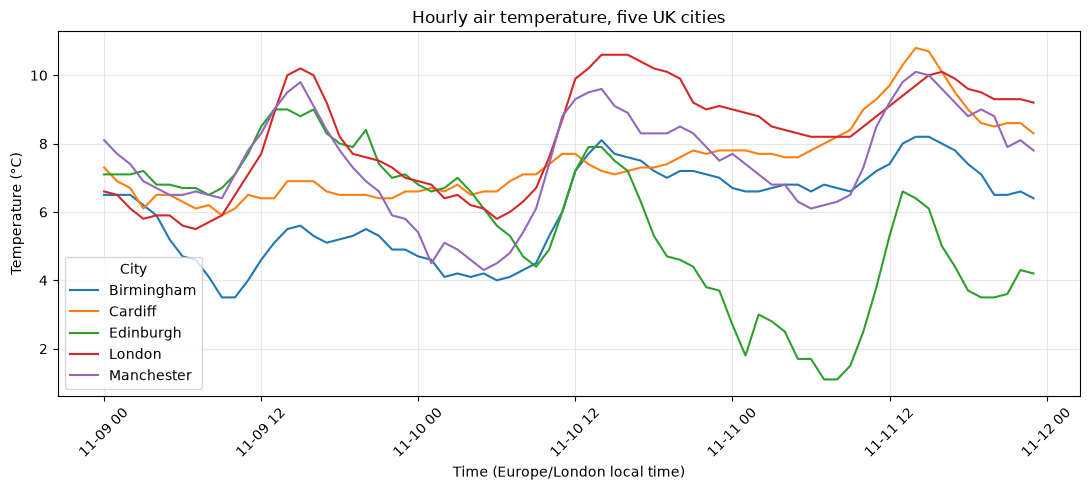

In [18]:
plot_df = df.copy()
plot_df["time"] = pd.to_datetime(plot_df["time"])
plot_df = plot_df.drop_duplicates(subset=["city", "time"], keep="last")

plt.figure(figsize=(11, 5))
for city, group in plot_df.groupby("city"):
    plt.plot(group["time"], group["temperature_2m"], label=city)

plt.title("Hourly air temperature, five UK cities")
plt.xlabel("Time (Europe/London local time)")
plt.ylabel("Temperature (°C)")
plt.legend(title="City")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Findings

1. **`time` is loaded as text, not a datetime.** The API sends strings like `2026-11-10T14:00`, so pandas stores them as text. They must be converted with `pd.to_datetime` before sorting, plotting or comparing times.
2. **Units are not in the column names.** Names like `temperature_2m` don't say °C. The units live separately in `hourly_units` (°C, %, mm, km/h), so they must be recorded in the data dictionary or they are lost.
3. **`weather_code` is a number that needs decoding.** Values like 3 or 61 mean nothing to a dashboard user. A WMO lookup table (code → description) is needed. My data has ___ distinct codes.
4. **Overlapping extract runs create duplicate (city, time) rows.** Each run asks for yesterday and today, so runs on nearby days share hours. My data has ___ duplicate rows, which must be removed (keeping the latest) in Task 1.5.
5. **Each file mixes past and forecast hours.** With `past_days=1` and `forecast_days=1`, half the rows already happened and half are forecasts. Forecasts can change on the next run, so the "keep the latest" rule matters.

Values are realistic: temperatures range from ___ to ___ °C across the five cities, with ___ missing values.